In [ ]:
"""
Let's see if I can inspect the df results but better this time
also fourier stuff is in here
"""

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

In [2]:
import plot_time_series as pts
import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from scipy.signal import find_peaks

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [8]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

In [79]:
from scipy.fft import rfft, irfft, rfftfreq

In [4]:
# okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("sobelratio")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df_sobel = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df_sobel

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio
0,0,34,34,ztf_20221020154120_000640_zi_c09_x_0017.,pos,173.500000,592.000000,6.0,4,22.759903
1,1,56,56,ztf_20221020154120_000640_zi_c09_x_0017.,pos,307.000000,592.000000,5.0,4,19.525473
2,2,71,71,ztf_20221020154120_000640_zi_c09_x_0017.,pos,399.076923,592.230769,13.0,4,12.377268
3,3,77,77,ztf_20221020154120_000640_zi_c09_x_0017.,pos,426.833333,592.166667,6.0,4,20.345509
4,4,85,85,ztf_20221020154120_000640_zi_c09_x_0017.,pos,463.000000,1751.833333,18.0,4,16.250433
...,...,...,...,...,...,...,...,...,...,...
614006,173,508,508,ztf_20221020138241_000686_zi_c15_x_0029.,both,2887.000000,523.000000,5.0,1,19.482388
614007,174,510,510,ztf_20221020138241_000686_zi_c15_x_0029.,both,2903.500000,523.250000,8.0,1,20.777689
614008,175,514,514,ztf_20221020138241_000686_zi_c15_x_0029.,both,2951.666667,523.333333,27.0,1,12.660818
614009,176,517,517,ztf_20221020138241_000686_zi_c15_x_0029.,both,2972.625000,523.375000,8.0,1,26.944208


In [5]:
nocrs = concatenated_df_sobel[concatenated_df_sobel["sobel_ratio"] > 5]

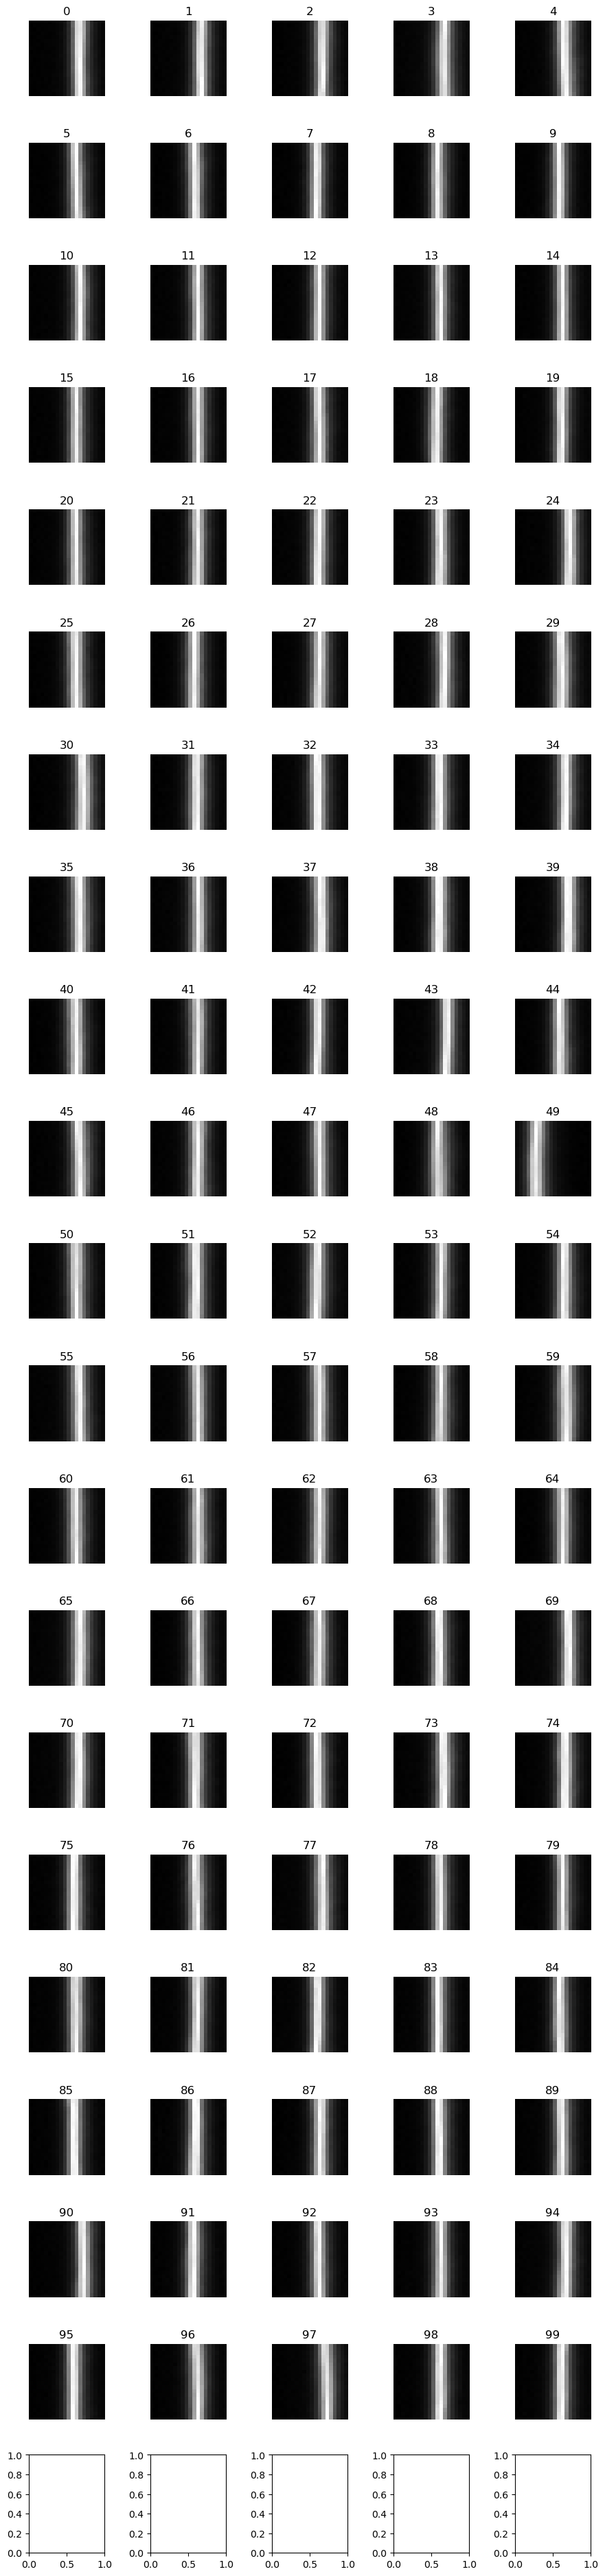

In [190]:
rff.inspect_df_with_quadrant(nocrs[:100], "1020")

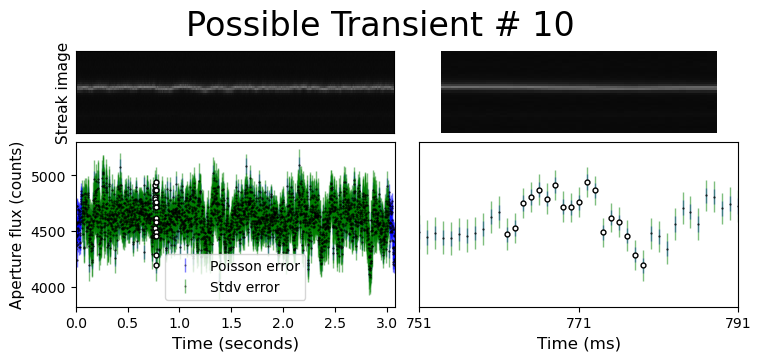

In [30]:
rff.plot_time_series_again_aperture(nocrs, 10, "1020", 2, tracking=True)

In [7]:
# so we need a bunch of streak fluxes


direcname = "1020"
half_aperture = 2
tracking = False
wideval = half_aperture
wid = 10
fname = "ztf_20221020154120_000640_zi_c09_x_0017." + "fits.fz"
row = int(1217.0) + 10  # we add 10 here bc that's the cnn offset of returned values
# col = int(df.iloc[index]["col_from_nn"])+10

quad = int(4)

fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)
path = fpath + fname
hdul = fits.open(path)
# print(path)
file1_array = hdul[quad].data
# norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
image = file1_array

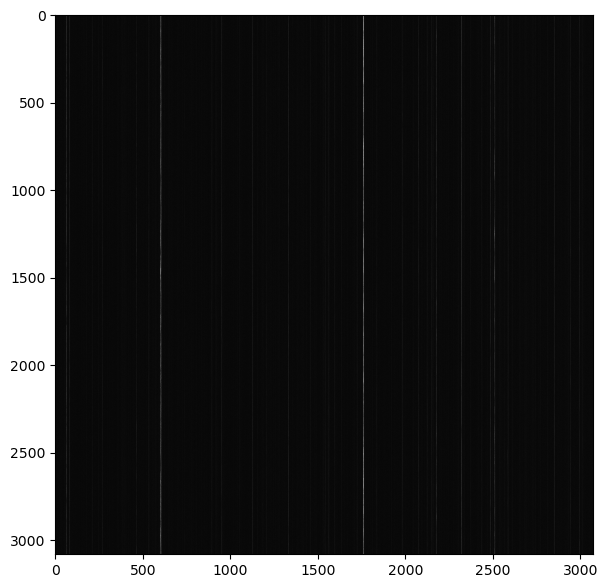

In [28]:
plt.imshow(np.sqrt(image))

In [10]:
peaks, _ = find_peaks(
    image[1000, :], height=500
)  # Adjust height threshold for your data

In [13]:
col = int(peaks[peakindex])


def get_tot_streak(image, col, tracking, half_aperture=2):
    """ """
    # row = int(df.iloc[index]["row_from_nn"])+10 #we add 10 here bc that's the cnn offset of returned values
    # col = int(df.iloc[index]["col_from_nn"])+10
    # col = int(peaks[peakindex])
    row = 1500  # for calculating avg
    background = rff.get_image_background(image)
    imagenobackground = image - np.full(np.shape(image), background)
    if tracking == False:
        zeropoint = col - 7
        averages = np.average(
            imagenobackground[row - 50 : row + 50, zeropoint : zeropoint + 14], axis=0
        )
        maxind = np.argmax(averages)
        tot2 = np.zeros(imagenobackground.shape[0])
        for r in range(
            0, imagenobackground.shape[0]
        ):  # this should be each row, probably
            maxcol = zeropoint + maxind
            combined = imagenobackground[r, maxcol]
            for i in range(1, half_aperture + 1):
                combined += imagenobackground[r, maxcol - i]
                # combined+=imagenobackground[r, maxcol+i]
            tot2[r] = combined
        return tot2

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 10
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 20]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, half_aperture + 1):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = combined

    return tot

In [14]:
all_streaks_tracking = []
for i in range(len(peaks)):
    tot = get_tot_streak(image, i, tracking=True)
    all_streaks_tracking.append(tot)

In [15]:
all_streaks_notracking = []
for i in range(len(peaks)):
    tot = get_tot_streak(image, i, tracking=False)
    all_streaks_notracking.append(tot)

In [16]:
?rff.get_stdvs

Signature: rff.get_stdvs(tot, do_all=True, df=None, index=None)
Docstring:
takes tot
do_all: if true, calculates the stdv for every point
if false, calculates the stdv around the detection
if do_all=false, must include df and index
File:      ~/review_findings_functions.py
Type:      function

In [18]:
avstds_2_tracking = np.zeros(len(all_streaks_notracking))
avgbrightness_2_tracking = np.zeros(len(all_streaks_notracking))
avg_2_tracking = np.zeros(len(all_streaks_notracking))
for i in range(len(all_streaks_notracking)):
    # tot, maxcol = get_tot(nocrs, index, '1020', half_aperture=2, tracking=True)
    tot = all_streaks_tracking[i]
    stdvs = rff.get_stdvs(tot, do_all=True)
    avstd = np.average(stdvs[61:-60])
    avgbrightness_2_tracking[i] = np.average(tot)
    avstds_2_tracking[i] = avstd
    avg_2_tracking[i] = avstd / np.average(tot)

In [20]:
avstds_2_notracking = np.zeros(len(all_streaks_notracking))
avgbrightness_2_notracking = np.zeros(len(all_streaks_notracking))
avg_2_notracking = np.zeros(len(all_streaks_notracking))
for i in range(len(all_streaks_notracking)):
    # tot, maxcol = get_tot(nocrs, index, '1020', half_aperture=2, tracking=True)
    tot = all_streaks_notracking[i]
    stdvs = rff.get_stdvs(tot, do_all=True)
    avstd = np.average(stdvs[61:-60])
    avgbrightness_2_notracking[i] = np.average(tot)
    avstds_2_notracking[i] = avstd
    avg_2_notracking[i] = avstd / np.average(tot)

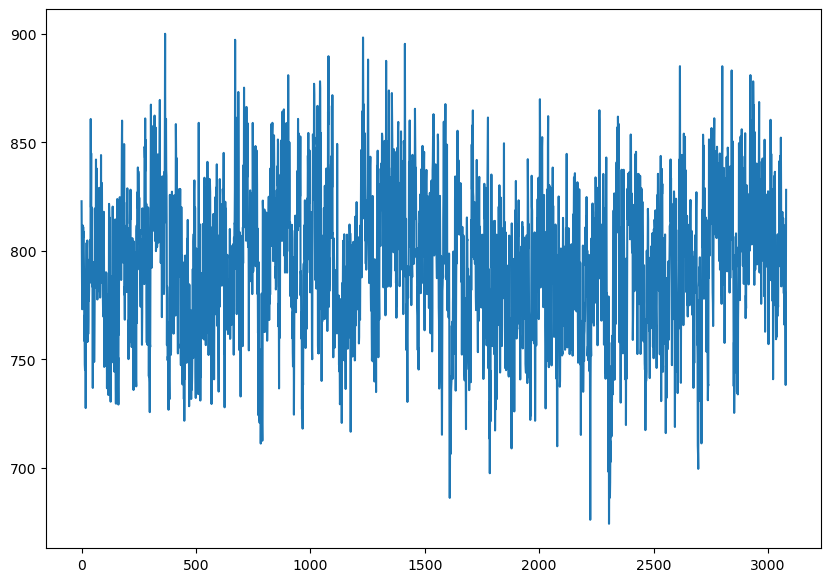

In [27]:
plt.plot(all_streaks_tracking[0])

In [22]:
print("no tracking, average of stdv/mean: ", np.average(avg_2_notracking))
print("stdv of that array: ", np.std(avg_2_notracking))
print("\n")

print("with tracking, average of stdv/mean: ", np.average(avg_2_tracking))
print("stdv of that array: ", np.std(avg_2_tracking))

no tracking, average of stdv/mean:  0.11159712767996992
stdv of that array:  0.0493879306435519


with tracking, average of stdv/mean:  0.032643768835325764
stdv of that array:  0.0033505869506034996
